##### 2-1. 합성데이터 생성
<pre style="font-size:16px">
# colab -> Colab CPU -> terminal
wget https://raw.githubusercontent.com/code-archive-git/ai/refs/heads/main/production/data/vibration.npz
</pre>

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 저장된 파일 불러오기
data = np.load("/content/vibration.npz")
# 학습(정상 300개), 시험(정상 200개),시험(비정상 30개), 샘플링주파수 5000
data # train, test_normal, test_anom, fs

NpzFile '/content/vibration.npz' with keys: train, test_normal, test_anom, fs

In [2]:
fs = data['fs']
print(fs) # 스펙트럼 폭을 결정한다.

5000


#### 2-2. [1단계] 신호 특징추출 (FFT · 통계량)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# 파형의 뾰족한 정도(kurtosis)와 좌우 비대칭 정도(skew)를 계산
from scipy.stats import kurtosis, skew

# 에너지를 따로 집계할 주파수 구간(Hz) 4개를 (시작Hz, 끝Hz) 튜플 리스트로 정의
BANDS = [(0, 100), (100, 500), (500, 1500), (1500, 2500)]

In [4]:
# 특징 추출 함수 extract(x)
# 시간 파형 → 표 형태 특징(Tabular Feature) 변환
# 전체 에너지(rms), 최대 진폭(peak), 뾰족함(kurtosis), 비대칭(skew), 첨두율(crest)과 주파수 대역별 에너지(band_...)
# DataFrame을 생성 후 반환
def extract(x): # x : 진동 신호 1개 윈도우(길이 5,000의 1차원 배열)
    # 0 ~ 5000 까지 분석할 주파수 범위 생성
    freq = np.fft.rfftfreq(len(x), 1 / fs)
    # 주파수를 추출 -> 허수부를 버리고(abs), 데이터 누적으로 인한 왜곡을 없애고(/len), 진종폭 적용(*2)
    amp = np.abs(np.fft.rfft(x)) / len(x) * 2
    # 각 지표 만들기
    df = {
        'rms': np.sqrt(np.mean(x ** 2)), # sqrt(mean(v**2))
        'peak': np.max(np.abs(x)), # max(abs(v))
        'kurtosis': kurtosis(x), 
        'skew': skew(x)
    }
    df['crest'] = df['peak'] / df['rms'] # peak/rms

    for lo, hi in BANDS: # 주파수 대역 [(0, 100), (100, 500), (500, 1500), (1500, 2500)]
        # 특정 주파수 구간에 해당하면 제곱(진폭**2 == 주파수별 에너지)
        df[f'b_{lo}_{hi}'] = np.sum(amp[(freq >= lo) & (freq < hi)] ** 2)
    return df


In [5]:
# 전달 받은 데이터를 이용해 데이터 프레임 생성
def to_df(arr):
    rows = []
    for x in arr:
        rows.append(extract(x))
    return pd.DataFrame(rows)
        

In [6]:
X_train = to_df(data['train'])
X_normal = to_df(data['test_normal'])
X_anom =  to_df(data['test_anom'])

# X_train.head()
# X_normal.head()
# X_anom.head()


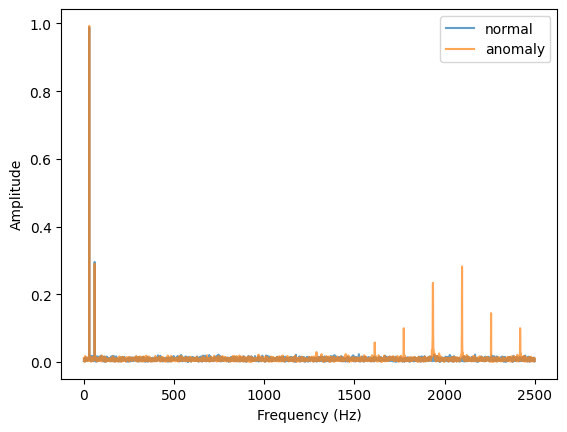

In [7]:

# 정상 vs 이상 스펙트럼 비교
# 정상 첫 번째 샘플('normal')과 가장 이상한 샘플('anomaly') - 첨도가 제일 높다는건 뭔가 튄다는 뜻 이므로
for name, x in [('normal', data['test_normal'][0]), 
                ('anomaly', data['test_anom'][X_anom['kurtosis'].idxmax()])]:
    # 주파수 대역(X 좌표)
    freq = np.fft.rfftfreq(len(x), 1 / fs)
    # Y 좌표는 진폭을 에너지로 표현
    plt.plot(freq, np.abs(np.fft.rfft(x)) / len(x) * 2, label=name, alpha=0.7)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

#### 2-3. [2단계] 정상 baseline 학습

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# X_train 을 이용하여 데이터 분할
X_fit, X_val = train_test_split(X_train, test_size=0.2, random_state=0)

# 1) 통계적 관리한계 : 특징별 z-score 의 최대값
# X_fit의 각 특징 컬럼별 평균(mu)과 표준편차(sd)를 계산
mu, sd = X_fit.mean(), X_fit.std()

def stat_score(X):
    # 입력 표 X의 각 값에서 정상 평균 mu를 빼고 표준편차 sd로 나눈 뒤(z-score), 절댓값(.abs())을 취하고, 
    # 행(axis=1, 즉 샘플 1개) 기준으로 가장 크게 벗어난 특징의 값(.max(axis=1))을 1차원 NumPy 배열(.values)로 반환
    return ((X - mu) / sd).abs().max(axis=1).values

In [9]:
# 2) IsolationForest
iso = IsolationForest(n_estimators=300, random_state=0).fit(X_fit)

In [10]:
# 3) One-Class SVM
ocsvm = make_pipeline(StandardScaler(), OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')).fit(X_fit)

#### 2-4. [3단계] 이상 스코어링

In [11]:
from sklearn.metrics import roc_auc_score

# IsolationForest와 OneClassSVM 의 결과는 - 처리 하여 뒤집는다.
SCORERS = {
    'Stat(3σ)'      : stat_score,
    'IsolationForest': lambda X: -iso.decision_function(X),
    'OneClassSVM'    : lambda X: -ocsvm.decision_function(X),
}

# np.r_로 두 배열의 앞쪽 len(X_normal)(200)개는 정상(0), 뒤쪽 len(X_anom)(30)개는 이상(1)이 됩니다.
# test 정상(200) + test 비정상(30)
y_eval = np.r_[np.zeros(len(X_normal)), np.ones(len(X_anom))]
# print(y_eval)

for name, f in SCORERS.items():
    # 함수로 인한 평가 - 정상 평가 점수 f(X_normal) , 이상 평가 점수 f(X_anom)
    s = np.r_[f(X_normal), f(X_anom)]
    # 정답과 비교
    print(f'{name:16s} ROC-AUC = {roc_auc_score(y_eval, s):.3f}')

Stat(3σ)         ROC-AUC = 0.991
IsolationForest  ROC-AUC = 0.964
OneClassSVM      ROC-AUC = 0.979


#### 2-5. [4단계] 임계 트레이드오프 실습

In [12]:
rows = []
for name, f in SCORERS.items():
    # 모델 실행 함수를 하나씩 꺼내 각 데이터를 이용해 실행
    """
    val: 임계값 산출 기준이 될 정상 검증 데이터(X_val)의 이상 점수
    nor: 실제 오탐률을 검증할 평가용 정상 데이터(X_normal)의 이상 점수
    ano: 실제 재현율을 검증할 평가용 이상 데이터(X_anom)의 이상 점수
    """
    val, nor, ano = f(X_val), f(X_normal), f(X_anom)
    for p in [95, 99, 99.5, 99.9]: # 허용할 정상 오탐률 수준
        # np.percentile(데이터, 백분위수) : 오름차순 정렬 시, 앞에서부터 몇 % 위치에 있는 값(백분위수)인지를 찾아줌
        thr = np.percentile(val, p) # (점수, 95): 하위 95% 위치의 점수 = 상위 5% 커트라인
        rows.append({'model': name, #모델명
                     'percentile': p, # 오탐률 수준
                     'threshold': thr, #임계값
                     '재현율(주입이상)': (ano > thr).mean(),
                     '오탐률(정상)': (nor > thr).mean()})

sens = pd.DataFrame(rows)
print(sens.round(3))        # → 임계 민감도 분석표 (산출물)

              model  percentile  threshold  재현율(주입이상)  오탐률(정상)
0          Stat(3σ)        95.0      2.652      0.933    0.055
1          Stat(3σ)        99.0      2.733      0.933    0.045
2          Stat(3σ)        99.5      2.735      0.933    0.045
3          Stat(3σ)        99.9      2.737      0.933    0.045
4   IsolationForest        95.0      0.005      0.900    0.110
5   IsolationForest        99.0      0.033      0.867    0.025
6   IsolationForest        99.5      0.039      0.867    0.025
7   IsolationForest        99.9      0.043      0.867    0.025
8       OneClassSVM        95.0      0.026      0.933    0.105
9       OneClassSVM        99.0      0.045      0.933    0.055
10      OneClassSVM        99.5      0.051      0.933    0.045
11      OneClassSVM        99.9      0.056      0.933    0.040


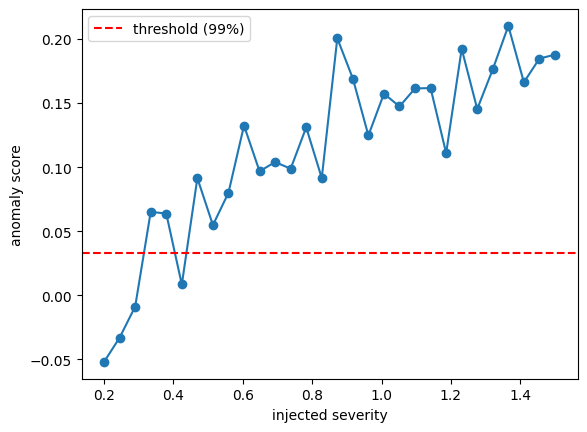

In [13]:
# 심각도별 탐지 여부 : 어느 정도 미세한 이상부터 잡히는가
# 임계값 추출（정상 검증 점수의 99% 백분위수를 커트라인）
thr = np.percentile(SCORERS['IsolationForest'](X_val), 99)

severity = np.linspace(0.2, 1.5, 30) # 심각도를 0.2~1.5 까지 30개 만듬(데이터에서 심각도를 준것과 똑같이 맞춤)
# 심각도별 이상점수 측정
plt.plot(severity, SCORERS['IsolationForest'](X_anom), 'o-')
plt.axhline(thr, color='r', linestyle='--', label='threshold (99%)')
plt.xlabel('injected severity')
plt.ylabel('anomaly score')
plt.legend()
plt.show()

#### 2-6. [5단계] 알림 로직

In [ ]:
# 실제 설비 가동 상황을 모사해 정상 데이터 100개 뒤에 점차 심해지는 이상 데이터 30개를 시간 순서대로 이어 붙인 가상 스트림(stream)을 만든 뒤, N-of-M 규칙과 2단계 임계값(99%, 99.9%)을 적용했을 때 언제부터 주의/경보가 울리고 정상 구간에서 오알람이 몇 건이나 억제되는지 검증하는 코드입니다.

# 실제 설비 가동 상황을 가정 -> 정상 데이터 100개 뒤에 점차 심해지는 이상 데이터 30개를 이어붙임
stream = pd.concat([X_normal.iloc[:100], X_anom], ignore_index=True)
 # 이상점수 산출: 이동 창 연산(.rolling())을 쓰기 위해 pandas Series로 변환
score = pd.Series(SCORERS['IsolationForest'](stream))
print(score)

0      0.117265
1     -0.081179
2     -0.076554
3     -0.059875
4     -0.076482
         ...   
125    0.176409
126    0.210227
127    0.166245
128    0.184792
129    0.187797
Length: 130, dtype: float64


In [16]:
# N-of-M 규칙 함수 정의
def n_of_m(over, n=3, m=5): # 최근 m개 중 n개 이상 임계값을 초과했는지 판정
    # rolling(m).sum(): 최근 5개(m=5) 초과 횟수(over) 합산
    # 그 합계가 n(3)번 이상 이면 True
    return over.astype(int).rolling(m).sum() >= n

In [17]:
# 임계값 계산의 기준이 될 정상 검증 데이터(X_val)의 이상 점수를 구한다.
val = SCORERS['IsolationForest'](X_val)
# 정상 검증 점수의 99% 를 주의 임계값(thr_warn), 99.9% 를 경고 임계값(thr_alarm)으로 설정
thr_warn, thr_alarm = np.percentile(val, 99), np.percentile(val, 99.9)

In [ ]:
# score 가 thr_alarm, 이나 thr_alarm 을 초과하면 그에 맞는 메시지를 생성
level = np.where(n_of_m(score > thr_alarm), '경보', np.where(n_of_m(score > thr_warn), '주의', '정상'))
# index, score, level 데이터 프레임을 만든다.
alarm_log = pd.DataFrame({'window': stream.index, 'score': score, 'level': level})
# 정상이 아닌 알람만 구분해서 10개 보여준다.
print(alarm_log[alarm_log['level'] != '정상'].head(10))
# 100 개 까지는 정상으로 만든 데이터, 여기에 혹시 정상이 아니라고 해 놓은게 있는지 확인(오알람)
print('정상 구간 오알람 수 :', (alarm_log.loc[:99, 'level'] != '정상').sum())

     window     score level
106     106  0.091479    경보
107     107  0.054828    경보
108     108  0.080039    경보
109     109  0.132531    경보
110     110  0.096786    경보
111     111  0.104031    경보
112     112  0.098812    경보
113     113  0.131077    경보
114     114  0.091532    경보
115     115  0.200588    경보
정상 구간 오알람 수 : 0
